# 01 · Data overview: what is in the FIFA data and what can go wrong

Before we build any model, we need to know our data well. This notebook answers three questions:

1. **What does one row mean?** What information do we have about each player?
2. **Is the data clean?** Are there duplicates, missing values, strange numbers?
3. **What patterns should the models respect?** For example, how market value depends on skill, age and league.

Everything here uses the cleaned file `data/processed/players.parquet`, made by `src/prepare_data.py`
from the original 5.6 GB Kaggle file. If you don't have it yet, run `python src/download_data.py` and then
`python src/prepare_data.py` from the project folder.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

DATA = Path("../data/processed/players.parquet")

# One shared chart style for the whole project: one main color, light grid, no box around the plot
BLUE, INK_2, MUTED, GRID = "#2a78d6", "#52514e", "#c3c2b7", "#e6e5e0"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 12,
})

def euro(x, _pos=None):
    """Format money for axis labels: 1_500_000 -> '€1.5M'."""
    if x >= 1e6:
        return f"€{x / 1e6:.3g}M"
    if x >= 1e3:
        return f"€{x / 1e3:.3g}K"
    return f"€{x:g}"

EURO = FuncFormatter(euro)
pd.set_option("display.max_columns", 30)

## 1. What one row means

The original file had about **10 million rows**. EA Sports updates player ratings almost every week during
a game's life, and the file stored every single update. A player like Messi appeared about 60 times
for one FIFA version alone.

We don't need weekly changes, so the cleaning script kept only **two snapshots per player per FIFA version**:

- `start`: the earliest update of the version, around the game's release in late August or September.
- `end`: the latest update, around the end of the football season, close to the summer transfer window.

So one row is **one player, in one FIFA version, at one moment (start or end of the season)**.
The column `season_start` translates the FIFA version into a real season: FIFA 20 covers the 2019/20 season,
so `season_start = 2019`.

In [2]:
players = pd.read_parquet(DATA)
print(f"{len(players):,} rows, {players.shape[1]} columns")
players.groupby(["fifa_version", "snapshot"], observed=True).size().unstack()

393,866 rows, 78 columns


snapshot,end,start
fifa_version,,
15,20361,20361
16,21347,21347
17,21010,21010
18,21831,21831
19,22074,22074
20,22214,22214
21,23672,23672
22,23803,23803
23,20621,20621


Every version has the same number of players in both snapshots, about 20 to 24 thousand. Let's look at one
famous player across the years to get a feeling for the data. Watch how his rating, potential and price change:

In [3]:
mbappe = players[(players.short_name == "K. Mbappé") & (players.snapshot == "end")]
mbappe[["fifa_version", "season_start", "age", "club_name", "overall", "potential", "value_eur", "wage_eur"]]

,fifa_version,season_start,age,club_name,overall,potential,value_eur,wage_eur
100014,17,2016,17.0,Monaco,79.0,92.0,17000000.0,40000.0
140555,18,2017,18.0,Paris Saint Germain,84.0,94.0,47000000.0,80000.0
182528,19,2018,19.0,Paris Saint Germain,88.0,95.0,82000000.0,100000.0
224791,20,2019,20.0,Paris Saint Germain,89.0,95.0,93500000.0,150000.0
268196,21,2020,21.0,Paris Saint Germain,90.0,95.0,185500000.0,160000.0
314156,22,2021,22.0,Paris Saint Germain,91.0,95.0,194000000.0,230000.0
360196,23,2022,23.0,Paris Saint Germain,91.0,95.0,190500000.0,230000.0


### The columns, in plain words

The file has 78 columns. They fall into a few groups:

- **Identity:** `player_id` (the reliable key, because names can repeat), `short_name`, `long_name`, `dob`, `nationality_name`.
- **Club and contract:** `league_id`, `league_name`, `league_level` (1 = top division), `club_team_id`, `club_name`,
  `club_position` (where he plays in the club's lineup; `SUB` means substitute and `RES` means reserve), `club_loaned_from`,
  `club_contract_valid_until_year` and our own `contract_years_left`.
- **Money:** `value_eur` (EA's estimate of market value), `wage_eur` (weekly wage), `release_clause_eur`.
- **Overall quality:** `overall` is the current level from 0 to 100, and `potential` is how good EA thinks he can become.
- **Six summary stats:** `pace`, `shooting`, `passing`, `dribbling`, `defending`, `physic`.
- **About 35 detailed skills:** everything from `attacking_finishing` to `mentality_interceptions` and `goalkeeping_reflexes`.
  These describe *how* a player plays, so they will matter most when we group players by style.
- **Our added columns:** `season_start`, `main_position` (the first position listed), `position_group`
  (GK, DEF, MID or FWD) and `contract_years_left`.

For most of this notebook we look at a single season to keep things simple: the **end of FIFA 22** (summer 2022),
the latest season that ends inside our data. FIFA 23's last update is from January 2023, the middle of the season.

In [4]:
s22 = players[(players.fifa_version == 22) & (players.snapshot == "end")].copy()
print(f"FIFA 22, end of season: {len(s22):,} players")

FIFA 22, end of season: 23,803 players


## 2. Is the data clean?

### Duplicates

Each player should appear only once per version and snapshot. If the cleaning script worked, this count is zero:

In [5]:
players.duplicated(["player_id", "fifa_version", "snapshot"]).sum()

np.int64(0)

### Missing values

Next, which columns have empty cells, and how many? Below is the share of missing values in each column
that has any (0.11 means 11% of players have no value there).

In [6]:
missing = s22.isna().mean().sort_values(ascending=False)
missing[missing > 0].round(3).to_frame("share_missing")

,share_missing
club_loaned_from,0.940
goalkeeping_speed,0.888
player_traits,0.512
dribbling,0.112
shooting,0.112
passing,0.112
physic,0.112
pace,0.112
defending,0.112
release_clause_eur,0.066


A missing value is not always an error. Usually it has a reason, and the reason decides what we should do with it.
Let's check the suspicious ones.

**The six summary stats (`pace`, `shooting` and so on) are missing for about 11% of players.** That is roughly
the share of goalkeepers. If so, it makes sense: FIFA shows goalkeepers with diving and reflexes instead of pace and shooting.

In [7]:
pd.crosstab(s22.position_group, s22.pace.isna(), normalize="index").round(2).rename(
    columns={False: "pace present", True: "pace missing"}
)

pace,pace present,pace missing
position_group,,
DEF,1.0,0.0
FWD,1.0,0.0
GK,0.0,1.0
MID,1.0,0.0


Our guess was right: only goalkeepers have no summary stats. This is the first sign that **goalkeepers must be
handled separately**, since their skills are on a completely different scale.

**`club_loaned_from` is missing for about 94% of players.** Here an empty value means "not on loan", so it's
information, not a gap. **`player_traits`** works the same way: empty means the player has no special traits.

**`value_eur` is missing for about 0.5% of players.** Let's see whether these are players without a club:

In [8]:
pd.crosstab(s22.value_eur.isna(), s22.club_name.isna(),
            rownames=["value missing"], colnames=["no club"])

no club,False,True
value missing,,
False,23674,0
True,14,115


Almost all players without a value are players without a club (free agents), so EA gives no price to a player nobody
owns. Only 14 players have a club and no value. Since there are so few, **we'll drop these rows when we model market
value**. Losing about 130 of 23,803 players changes nothing.

### Outliers: strange numbers that may still be true

An outlier is a value far away from the others. Before deleting one, we check whether it is a mistake or just rare.

In [9]:
cols = ["short_name", "club_name", "age", "overall", "value_eur"]
display(s22.nlargest(5, "value_eur")[cols])
display(players[players.snapshot == "end"].nlargest(3, "age")[cols + ["fifa_version"]])

,short_name,club_name,age,overall,value_eur
314156,K. Mbappé,Paris Saint Germain,22.0,91.0,194000000.0
316382,E. Haaland,Borussia Dortmund,20.0,88.0,143500000.0
309392,M. Salah,Liverpool,29.0,91.0,129000000.0
307156,K. De Bruyne,Manchester City,30.0,91.0,125500000.0
306617,R. Lewandowski,FC Bayern München,32.0,92.0,119500000.0


,short_name,club_name,age,overall,value_eur,fifa_version
2165,D. Beasant,Stevenage,55.0,40.0,4000.0,15
321541,K. Miura,Yokohama,54.0,56.0,NaN,22
276869,K. Miura,Yokohama,53.0,59.0,NaN,21


Both are real. Mbappé really was the most valuable player in 2022. The 55-year-old is Dave Beasant, a famous
former goalkeeper who was registered as a player at Stevenage, and the 54-year-old is Kazuyoshi Miura, who still
played professionally in Japan. These rows should stay, but they tell us two things:

- **Market value is extremely spread out**, from a few thousand euros to almost two hundred million. Section 3 deals with that.
- For a transfer recommendation we will filter players by realistic age anyway, so rare cases like Beasant won't matter.

### A hidden trap: league names are not unique

You might expect `league_name` to identify a league. It doesn't:

In [10]:
ids_per_name = s22.groupby("league_name", observed=True)["league_id"].nunique()
ids_per_name[ids_per_name > 1].to_frame("different leagues with this name")

,different leagues with this name
league_name,
Bundesliga,2
Premier League,4
Primera Division,4
Pro League,2
Serie A,2
Super League,4


"Serie A" is both the Italian and the Brazilian top division. "Premier League" is used for four countries. If we
grouped by name, we would mix Milan with Corinthians. **Always group by `league_id`** (and `club_team_id` for clubs,
since club names also change between updates).

Look at the four "Premier Leagues" more closely:

In [11]:
(s22[s22.league_name == "Premier League"]
 .groupby("league_id", observed=True)
 .agg(players=("player_id", "size"),
      clubs=("club_team_id", "nunique"),
      avg_overall=("overall", "mean"),
      example_club=("club_name", "first"))
 .round(1))

,players,clubs,avg_overall,example_club
league_id,,,,
13.0,787,20,69.800003,Manchester United
67.0,92,3,69.000000,CSKA Moskva
332.0,53,2,71.900002,Shakhtar Donetsk
347.0,71,2,66.000000,Kaizer Chiefs


The Ukrainian league has an even *higher* average rating than the English one (71.9 vs 69.8). Is Ukrainian football
stronger than English football?
No. EA has the license for **only two Ukrainian clubs**, Shakhtar and Dynamo Kyiv, and both are the best teams in their country.
The weaker clubs simply aren't in the game.

This is **selection bias**: our data is not a fair sample of world football. Top leagues are complete, but many smaller
leagues show only their best clubs. Any "league strength" number we compute from averages will overrate those leagues,
so we have to be careful when comparing players across leagues.

## 3. Patterns the models need to respect

### Market value is very skewed

Let's look at the distribution of market values on a normal scale and on a logarithmic scale.
A log scale compresses big numbers: each step means "ten times more" (€100K, €1M, €10M).

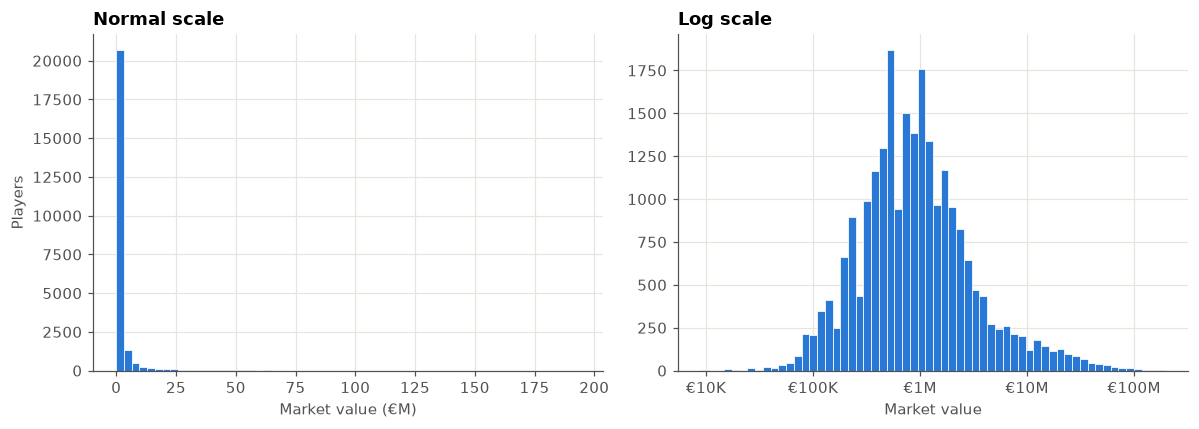

Median value: €850K,  mean value: €2.45M


In [12]:
value = s22.value_eur.dropna()
value = value[value > 0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.hist(value / 1e6, bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
ax1.set(title="Normal scale", xlabel="Market value (€M)", ylabel="Players")
ax2.hist(np.log10(value), bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
ax2.set_xticks([4, 5, 6, 7, 8], ["€10K", "€100K", "€1M", "€10M", "€100M"])
ax2.set(title="Log scale", xlabel="Market value")
plt.tight_layout()
plt.show()

print(f"Median value: {euro(value.median())},  mean value: {euro(value.mean())}")

On the normal scale almost every player is squeezed into the first bar, and a few stars stretch the axis far to the right.
On the log scale the shape becomes a normal-looking hill.

Notice that the **mean is about three times the median**. A few very expensive players pull the mean up, so the median
describes a "typical" player much better.

**What this means for the model:** if we predict the raw value, the error on Mbappé (millions) would dominate everything,
and the model would basically ignore cheap players, who are exactly the ones a small club can buy. So **we'll predict
the logarithm of the value**. An error then means "off by X percent" instead of "off by X euros", which is fair for
cheap and expensive players alike.

### Value grows very fast with skill

How does value depend on the `overall` rating? Each grey dot is one player, and the blue line is the median value at
each rating.

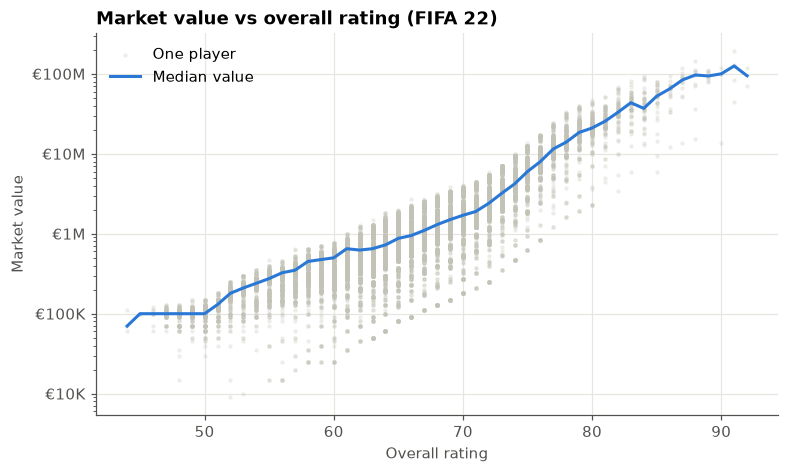

Between 60 and 85, each +1 overall point means about 20% higher value


In [13]:
d = s22[s22.value_eur > 0]
median_by_overall = d.groupby("overall")["value_eur"].median()

fig, ax = plt.subplots()
ax.scatter(d.overall, d.value_eur, s=4, alpha=0.2, color=MUTED, label="One player", rasterized=True)
ax.plot(median_by_overall.index, median_by_overall.values, color=BLUE, lw=2, label="Median value")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(EURO)
ax.set(title="Market value vs overall rating (FIFA 22)", xlabel="Overall rating", ylabel="Market value")
ax.legend(frameon=False, loc="upper left")
plt.show()

mid = d[d.overall.between(60, 85)]
slope = np.polyfit(mid.overall, np.log(mid.value_eur), 1)[0]
print(f"Between 60 and 85, each +1 overall point means about {np.exp(slope) - 1:.0%} higher value")

On a log scale the median line is close to a straight line. That means value grows **exponentially**: each extra rating
point multiplies the price by roughly the same factor, instead of adding a fixed amount. Going from 80 to 85 costs far
more euros than going from 60 to 65.

One detail: below a rating of about 50 the line is flat at €100K. EA seems to use a minimum price for weak players,
so values in that zone tell us nothing. Our candidates will be far above it anyway.

Look at how wide the cloud of dots is at a fixed rating. Players with the *same* overall can differ in price by ten times
or more. Some of that spread comes from age, position and league, which we check next. **The part of the spread that
those factors cannot explain is exactly what our Moneyball system is looking for.**

### Age: the same skill costs very different money

Let's take only players with a similar level (overall 72 to 76) and see how their median value changes with age.
We show only ages with at least 30 players, so that one unusual player can't move the line.

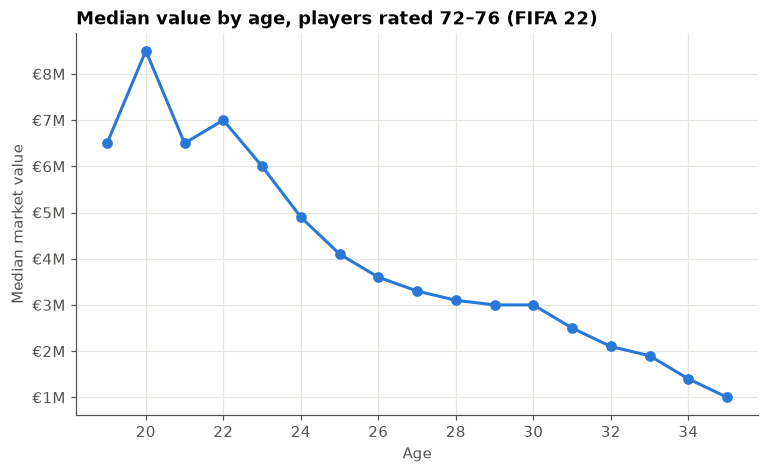

In [14]:
band = d[d.overall.between(72, 76)]
by_age = band.groupby("age")["value_eur"].agg(["median", "size"])
by_age = by_age[by_age["size"] >= 30]

fig, ax = plt.subplots()
ax.plot(by_age.index, by_age["median"], color=BLUE, lw=2, marker="o", ms=6)
ax.yaxis.set_major_formatter(EURO)
ax.set(title="Median value by age, players rated 72–76 (FIFA 22)", xlabel="Age", ylabel="Median market value")
plt.show()

For players of about the same quality, the young ones cost much more. The median price peaks around age 20 to 22
(the ages 19 to 22 jump around because there are fewer players there), falls quickly until about 26, stays fairly
flat until 30, and then drops again. A 20-year-old costs about three times as much as a 28-year-old with the same rating. Clubs pay for the future: a 21-year-old may still improve and can be sold again later,
while a 32-year-old will probably get worse.

**What this means for the model:** age must be a feature. Otherwise the model will flag every 32-year-old as a
"bargain", when he's simply cheap because he's old. It also raises a question for the team: does our club want
players who are good now (older, cheaper) or players who will be worth more later (younger, more expensive)?

### League: does the same skill cost different money in different leagues?

Now take players rated 70 to 74 and compare their median value across some well-known leagues.

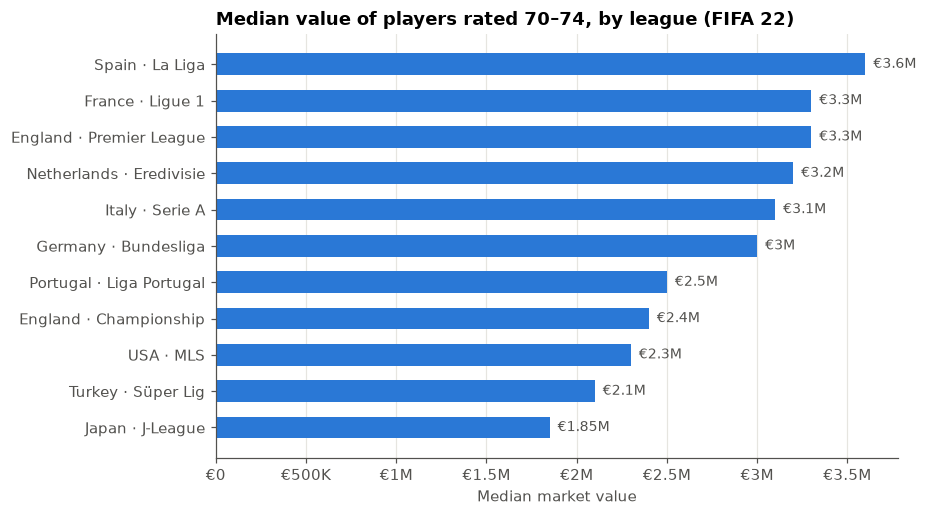

league_id,Japan · J-League,Turkey · Süper Lig,USA · MLS,England · Championship,Portugal · Liga Portugal,Germany · Bundesliga,Italy · Serie A,Netherlands · Eredivisie,England · Premier League,France · Ligue 1,Spain · La Liga
size,62,203,156,254,151,171,193,81,116,211,153


In [15]:
LEAGUES = {
    13: "England · Premier League", 14: "England · Championship", 53: "Spain · La Liga",
    31: "Italy · Serie A", 19: "Germany · Bundesliga", 16: "France · Ligue 1",
    308: "Portugal · Liga Portugal", 10: "Netherlands · Eredivisie", 68: "Turkey · Süper Lig",
    39: "USA · MLS", 349: "Japan · J-League",
}
band = d[d.overall.between(70, 74) & d.league_id.isin(LEAGUES)]
by_league = (band.groupby("league_id")["value_eur"].agg(["median", "size"])
             .rename(index=LEAGUES).sort_values("median"))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(by_league.index, by_league["median"], color=BLUE, height=0.6)
for name, row in by_league.iterrows():
    ax.text(row["median"], name, f"  {euro(row['median'])}", va="center", color=INK_2, fontsize=9)
ax.xaxis.set_major_formatter(EURO)
ax.grid(axis="y", visible=False)
ax.set(title="Median value of players rated 70–74, by league (FIFA 22)", xlabel="Median market value")
plt.show()

by_league[["size"]].T

At first sight, players of the same level are valued differently depending on where they play: roughly two times
more in La Liga than in the J-League. It's tempting to conclude "the league decides the price" and to go shopping in
"cheap" leagues.

**But careful: correlation is not causation.** Maybe the players in these leagues differ in some *other* way that
affects the price. Age is the obvious suspect, since we just saw how strongly it drives value. Let's look at the
typical age and potential of the same players:

In [16]:
(band.groupby("league_id")[["value_eur", "age", "potential"]].median()
 .rename(index=LEAGUES).sort_values("value_eur")
 .rename(columns={"value_eur": "median value", "age": "median age", "potential": "median potential"}))

,median value,median age,median potential
league_id,,,
Japan · J-League,1850000.0,28.0,71.0
Turkey · Süper Lig,2100000.0,28.0,73.0
USA · MLS,2300000.0,27.0,73.0
England · Championship,2400000.0,26.0,73.0
Portugal · Liga Portugal,2500000.0,26.0,74.0
Germany · Bundesliga,3000000.0,26.0,74.0
Italy · Serie A,3100000.0,26.0,74.0
Netherlands · Eredivisie,3200000.0,25.0,74.0
England · Premier League,3300000.0,27.0,74.0


There's the explanation. The "cheap" leagues have **older** players with **lower potential** (J-League: median age 28,
potential 71), and the "expensive" leagues have younger players with higher potential (Ligue 1: 25 and 76). The league
itself may not matter at all. It just *looks* important because it travels together with age and potential.

This is called **confounding**: a hidden third factor (here age and potential) creates a relationship between two
others (league and price). In notebook 03 we check it properly with a model, and indeed, once rating, potential and age
are known, the league changes EA's price by less than 1%.

**What this means for the project:** we can't simply buy "in cheap leagues". Before trusting any pattern, we have to ask
which hidden factor might explain it. This is one of the pitfalls the task asks us to discuss.

## 4. Following players over time: the basis for our backtest

The most valuable property of this dataset is that we can follow the same player through several seasons.
That lets us check our system honestly: make picks with old data, then look at what happened two years later.

Below we pair every player at the end of version *v* with the same player at the end of version *v + 2*. Versions 15 to 21
have such a partner; for FIFA 22 and 23, the "future" isn't in our data yet.

In [17]:
end = players[players.snapshot == "end"]
now = end[["player_id", "fifa_version", "age", "overall", "potential", "value_eur", "position_group"]]
later = (end[["player_id", "fifa_version", "overall", "value_eur"]]
         .assign(fifa_version=lambda x: x.fifa_version - 2))  # shift so v+2 lines up with v

now = now[now.fifa_version <= 21]
pairs = now.merge(later, on=["player_id", "fifa_version"], how="left", suffixes=("", "_in_2y"))
pairs["still_in_game"] = pairs.overall_in_2y.notna()
pairs["overall_change"] = pairs.overall_in_2y - pairs.overall

print(f"{len(pairs):,} player-seasons, {pairs.still_in_game.mean():.0%} of them are still in the game two years later")

152,509 player-seasons, 62% of them are still in the game two years later


Here are two pictures side by side: how much players improve in two years depending on their age, and how many of them
are still in the game two years later.

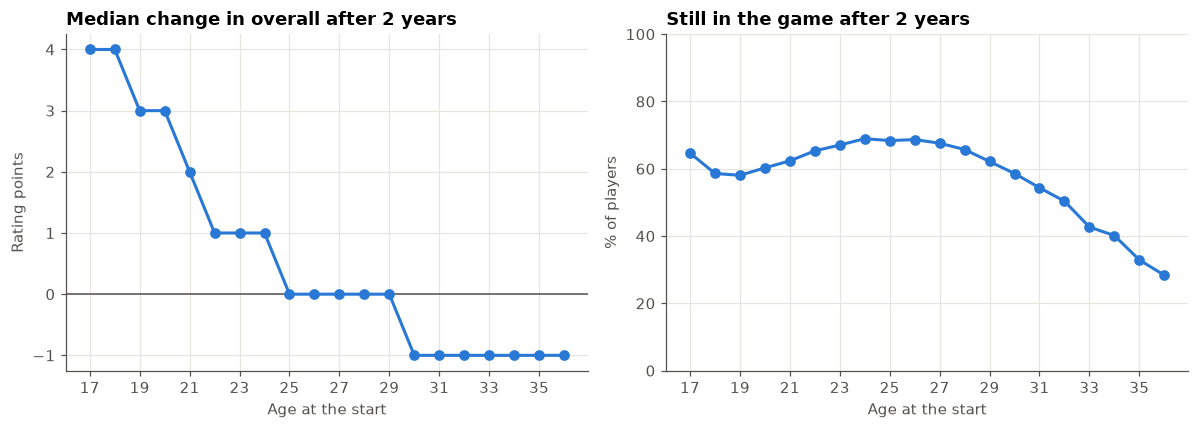

In [18]:
by_age = (pairs[pairs.age.between(17, 36)]
          .groupby("age")
          .agg(change=("overall_change", "median"), still=("still_in_game", "mean")))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.axhline(0, color=INK_2, lw=1)
ax1.plot(by_age.index, by_age.change, color=BLUE, lw=2, marker="o", ms=6)
ax1.set(title="Median change in overall after 2 years", xlabel="Age at the start", ylabel="Rating points")
ax2.plot(by_age.index, by_age.still * 100, color=BLUE, lw=2, marker="o", ms=6)
ax2.set(title="Still in the game after 2 years", xlabel="Age at the start", ylabel="% of players", ylim=(0, 100))
for ax in (ax1, ax2):
    ax.set_xticks(range(17, 37, 2))
plt.tight_layout()
plt.show()

**The left chart** shows the typical career curve: 17- and 18-year-olds gain about 4 points in two years, the gain shrinks
every year, it reaches zero at 25, stays at zero until 29, and from 30 players lose points. (The line moves in steps because
ratings are whole numbers, so the median change is a whole number too.) This is what our backtest will measure:
did the players our system picked grow *more* than similar players of the same age?

**The right chart** is a warning. Many players disappear from the game within two years: even at the "safest" ages
(24 to 27) about a third are gone, and by 36 more than two thirds. Young players disappear because
they never made it and were dropped from licensed squads, and old players because they retired. We don't know how they
would have developed.

This is called **survivorship bias**. If we only measure players who are still in the game, we only see the "survivors",
who are probably the ones who did well. Our backtest would look better than reality. The honest approach is to report
the drop-out rate for our picks too, and to count a disappeared player as a failure (or at least to show results both ways).

## Summary

| What we found | Why it matters for the project |
|---|---|
| One row = player × FIFA version × snapshot (start / end of season) | Use the `end` snapshot as "what the club knows at the transfer window" |
| No duplicates after cleaning | The weekly-update duplicates are gone, so they can't leak between train and test |
| Goalkeepers have no summary stats | Treat GK separately; compare players only inside their position group |
| `club_loaned_from` / `player_traits` empty = "no" | Missing here is information, not an error |
| Mbappé (€194M) and a 55-year-old are real | Keep them, but filter realistic ages for recommendations |
| League names repeat across countries | Always group by `league_id` and `club_team_id`, never by name |
| Some leagues include only their top clubs | Selection bias: league averages overrate small leagues |
| Market value is extremely skewed | Model `log(value)`, not raw euros |
| Value grows exponentially with overall | The same rating gap costs far more at the top |
| Same skill: younger = much more expensive | Age must be a model feature, or old players look like "bargains" |
| League price gaps disappear once age and potential are known | Confounding: always look for a hidden factor before trusting a pattern |
| Young players improve, older ones decline | This is what the backtest measures: growth beyond what age predicts |
| Many players leave the game within 2 years | Survivorship bias: count drop-outs in the backtest |

**Next:** notebook 02 builds the first ingredient of our Replacement Finder: a way to measure whether two players play
in the same style.